In [11]:
# CELL 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import joblib
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)
import tensorflow as tf
tf.random.set_seed(42)

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [12]:
# CELL 2: Heritage LSTM Predictor Class
class HeritageLSTMPredictor:
    def __init__(self):
        self.material_properties = self._define_material_properties()
        self.label_encoder = LabelEncoder()
        self.scaler_X = StandardScaler()
        self.scaler_temp = StandardScaler()
        self.scaler_humidity = StandardScaler()
        self.temp_model = None
        self.humidity_model = None
        self.feature_cols = None
        
    def _define_material_properties(self):
        """Define detailed material properties for each material set"""
        return {
            'Material1': {  # Bath stone + traditional materials
                'wall_conductivity': 1.8,
                'wall_density': 2200,
                'wall_specific_heat': 1000,
                'wall_thermal_mass': 2200 * 1000 * 0.36,
                'roof_conductivity': 1.5,
                'roof_density': 2500,
                'floor_conductivity': 1.7,
                'avg_conductivity': (1.8 + 1.5 + 1.7) / 3,
                'thermal_mass_factor': 'high'
            },
            'Material2': {  # Concrete block construction
                'wall_conductivity': 1.0,
                'wall_density': 1500,
                'wall_specific_heat': 840,
                'wall_thermal_mass': 1500 * 840 * 0.20,
                'roof_conductivity': 1.7,
                'roof_density': 2300,
                'floor_conductivity': 1.7,
                'avg_conductivity': (1.0 + 1.7 + 1.7) / 3,
                'thermal_mass_factor': 'medium'
            },
            'Material3': {  # Insulated construction
                'wall_conductivity': 0.035,
                'wall_density': 30,
                'wall_specific_heat': 1400,
                'wall_thermal_mass': 30 * 1400 * 0.25,
                'roof_conductivity': 0.04,
                'roof_density': 100,
                'floor_conductivity': 0.1,
                'avg_conductivity': (0.035 + 0.04 + 0.1) / 3,
                'thermal_mass_factor': 'low'
            }
        }
    
    def preprocess_location(self, filepath, material=None, datetime_col='Datetime'):
        """Enhanced preprocessing with more features"""
        # Load data
        df = pd.read_csv(filepath, dayfirst=True)
        filename = filepath.split('\\')[-1] if '\\' in filepath else filepath.split('/')[-1]
        print(f"{filename}: Raw rows = {len(df)}")
        
        # Add material column
        if material:
            df['Material'] = material
        
        # Convert datetime
        df[datetime_col] = pd.to_datetime(df[datetime_col], dayfirst=True, errors='coerce')
        df = df.dropna(subset=[datetime_col])
        df = df.sort_values(datetime_col)
        
        # Basic time features
        df['Year'] = df[datetime_col].dt.year
        df['Date'] = df[datetime_col].dt.date
        df['hour'] = df[datetime_col].dt.hour
        df['month'] = df[datetime_col].dt.month
        df['dayofweek'] = df[datetime_col].dt.dayofweek
        df['dayofyear'] = df[datetime_col].dt.dayofyear
        
        # Cyclical encoding for better temporal patterns
        df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
        df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
        df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
        df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
        df['day_sin'] = np.sin(2 * np.pi * df['dayofyear'] / 365)
        df['day_cos'] = np.cos(2 * np.pi * df['dayofyear'] / 365)
        
        # Enhanced lag features (multiple time steps)
        for lag in [1, 2, 3, 6, 12]:  # 1-12 hours back
            df[f'Outdoor_Temp_lag{lag}'] = df['Outdoor_Temp'].shift(lag)
            df[f'Outdoor_Humidity_lag{lag}'] = df['Outdoor_Humidity'].shift(lag)
            df[f'Indoor_Temp_lag{lag}'] = df['Indoor_Temp'].shift(lag)
            df[f'Indoor_Humidity_lag{lag}'] = df['Indoor_Humidity'].shift(lag)
        
        # Rolling statistics (multiple windows)
        for window in [3, 6, 12, 24]:  # 3-24 hours
            df[f'Outdoor_Temp_roll{window}_mean'] = df['Outdoor_Temp'].rolling(window).mean()
            df[f'Outdoor_Temp_roll{window}_std'] = df['Outdoor_Temp'].rolling(window).std()
            df[f'Outdoor_Humidity_roll{window}_mean'] = df['Outdoor_Humidity'].rolling(window).mean()
            df[f'Outdoor_Humidity_roll{window}_std'] = df['Outdoor_Humidity'].rolling(window).std()
        
        # Temperature differences and gradients
        df['Temp_Diff'] = df['Outdoor_Temp'] - df['Indoor_Temp']
        df['Humidity_Diff'] = df['Outdoor_Humidity'] - df['Indoor_Humidity']
        df['Temp_Gradient'] = df['Outdoor_Temp'].diff()
        df['Humidity_Gradient'] = df['Outdoor_Humidity'].diff()
        
        # Interaction features
        df['Temp_Humidity_Interaction'] = df['Outdoor_Temp'] * df['Outdoor_Humidity']
        df['Temp_Hour_Interaction'] = df['Outdoor_Temp'] * df['hour']
        df['Season_Temp_Interaction'] = df['Outdoor_Temp'] * df['month']
        
        # Weather condition categories
        df['Temp_Category'] = pd.cut(df['Outdoor_Temp'], 
                                   bins=[-np.inf, 5, 15, 25, np.inf], 
                                   labels=['Cold', 'Cool', 'Warm', 'Hot'])
        df['Humidity_Category'] = pd.cut(df['Outdoor_Humidity'], 
                                       bins=[-np.inf, 30, 60, 80, np.inf], 
                                       labels=['Dry', 'Comfortable', 'Humid', 'Very_Humid'])
        
        # Encode categorical variables
        df['Temp_Category'] = LabelEncoder().fit_transform(df['Temp_Category'].astype(str))
        df['Humidity_Category'] = LabelEncoder().fit_transform(df['Humidity_Category'].astype(str))
        
        # Handle missing values from lag/rolling computations
        df = df.fillna(method='ffill').fillna(method='bfill')
        
        return df
    
    def add_material_features(self, df):
        """Add material property features to the dataframe"""
        material_features = []
        
        for idx, row in df.iterrows():
            material = row['Material']
            props = self.material_properties[material]
            
            # Add material properties as features
            material_features.append({
                'wall_conductivity': props['wall_conductivity'],
                'wall_thermal_mass': props['wall_thermal_mass'],
                'avg_conductivity': props['avg_conductivity'],
                'thermal_mass_high': 1 if props['thermal_mass_factor'] == 'high' else 0,
                'thermal_mass_medium': 1 if props['thermal_mass_factor'] == 'medium' else 0,
                'thermal_mass_low': 1 if props['thermal_mass_factor'] == 'low' else 0,
            })
        
        material_df = pd.DataFrame(material_features)
        return pd.concat([df.reset_index(drop=True), material_df], axis=1)

    def load_and_preprocess_all_data(self, data_dir):
        """Load and preprocess all datasets"""
        datasets = []

        # Define file mappings (same as your Random Forest)
        file_mappings = {
            'Gatwick.csv': 'Material1', 'Gatwick02.csv': 'Material2', 'Gatwick03.csv': 'Material3',
            'Barcelona.csv': 'Material1', 'Barcelona02.csv': 'Material2', 'Barcelona03.csv': 'Material3',
            'Norway.csv': 'Material1', 'Norway02.csv': 'Material2', 'Norway03.csv': 'Material3',
            'Dubai.csv': 'Material1', 'Dubai02.csv': 'Material2', 'Dubai03.csv': 'Material3',
            'Singapore.csv': 'Material1', 'Singapore02.csv': 'Material2', 'Singapore03.csv': 'Material3',
            'Bath02.csv': 'Material2', 'Bath03.csv': 'Material3',
            'Bath.csv': 'Material1'  # Real data
        }

        for filename, material in file_mappings.items():
            filepath = f"{data_dir}\\{filename}"
            try:
                df = self.preprocess_location(filepath, material)
                df['Location'] = filename.split('.')[0].replace('02', '').replace('03', '')
                df['is_real_data'] = 1 if filename == 'Bath.csv' else 0
                datasets.append(df)
            except FileNotFoundError:
                print(f"File not found: {filepath}")
                continue

        # Combine all datasets
        combined_data = pd.concat(datasets, ignore_index=True)

        # Add material features
        combined_data = self.add_material_features(combined_data)

        # Encode categorical variables
        combined_data['Material_enc'] = self.label_encoder.fit_transform(combined_data['Material'])
        combined_data['Location_enc'] = LabelEncoder().fit_transform(combined_data['Location'])

        return combined_data

    def prepare_features_and_targets(self, data):
        """Prepare feature matrix and target variables"""
        # Define feature columns (excluding targets and metadata)
        exclude_cols = ['Indoor_Temp', 'Indoor_Humidity', 'Datetime', 'Year', 'Date', 'Material', 'Location']
        feature_cols = [col for col in data.columns if col not in exclude_cols]
        
        X = data[feature_cols]
        y_temp = data['Indoor_Temp']
        y_humidity = data['Indoor_Humidity']
        
        return X, y_temp, y_humidity, feature_cols
    
    def split_data_strategically(self, data, test_ratio=0.2):
        """Strategic data splitting for time series with real data focus"""
        # Sort by datetime
        data = data.sort_values('Datetime')
        
        # Separate real and synthetic data
        real_data = data[data['is_real_data'] == 1].copy()
        synthetic_data = data[data['is_real_data'] == 0].copy()
        
        # Use most recent real data for testing
        if len(real_data) > 0:
            real_split_idx = int(len(real_data) * (1 - test_ratio))
            real_train = real_data.iloc[:real_split_idx]
            real_test = real_data.iloc[real_split_idx:]
        else:
            real_train, real_test = pd.DataFrame(), pd.DataFrame()
        
        # Use synthetic data primarily for training
        synthetic_split_idx = int(len(synthetic_data) * 0.9)  # Keep 90% for training
        synthetic_train = synthetic_data.iloc[:synthetic_split_idx]
        synthetic_val = synthetic_data.iloc[synthetic_split_idx:]
        
        # Combine training data
        train_data = pd.concat([synthetic_train, real_train], ignore_index=True)
        # Use real test data as primary test set, synthetic validation as secondary
        test_data = real_test if len(real_test) > 0 else synthetic_val
        
        return train_data, test_data

    def create_sequences(self, X, y, sequence_length=24):
        """Create sequences for LSTM training"""
        X_seq, y_seq = [], []
        for i in range(len(X) - sequence_length + 1):
            X_seq.append(X[i:i + sequence_length])
            y_seq.append(y[i + sequence_length - 1])  # Predict the last value in sequence
        
        return np.array(X_seq), np.array(y_seq)

    def build_lstm_model(self, input_shape, target_name):
        """Build LSTM model"""
        print(f"Building LSTM model for {target_name}...")
        
        model = Sequential([
            LSTM(64, return_sequences=True, input_shape=input_shape),
            Dropout(0.2),
            LSTM(32, return_sequences=False),
            Dropout(0.2),
            Dense(16, activation='relu'),
            Dense(1)
        ])
        
        model.compile(
            optimizer=Adam(learning_rate=0.001),
            loss='mse',
            metrics=['mae']
        )
        
        return model

    def train_lstm_models(self, X_train, y_temp_train, y_humidity_train, 
                         X_val, y_temp_val, y_humidity_val, epochs=100):
        """Train both LSTM models"""
        print("🔧 Training LSTM models...")
        
        # Callbacks
        early_stopping = EarlyStopping(
            monitor='val_loss',
            patience=15,
            restore_best_weights=True,
            verbose=1
        )
        
        lr_scheduler = ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=10,
            min_lr=1e-6,
            verbose=1
        )
        
        # Train Temperature Model
        print("\n🌡️ Training Temperature Model...")
        self.temp_model = self.build_lstm_model(
            (X_train.shape[1], X_train.shape[2]), "Temperature"
        )
        
        temp_history = self.temp_model.fit(
            X_train, y_temp_train,
            validation_data=(X_val, y_temp_val),
            epochs=epochs,
            batch_size=32,
            callbacks=[early_stopping, lr_scheduler],
            verbose=1
        )
        
        # Train Humidity Model
        print("\n💧 Training Humidity Model...")
        self.humidity_model = self.build_lstm_model(
            (X_train.shape[1], X_train.shape[2]), "Humidity"
        )
        
        humidity_history = self.humidity_model.fit(
            X_train, y_humidity_train,
            validation_data=(X_val, y_humidity_val),
            epochs=epochs,
            batch_size=32,
            callbacks=[early_stopping, lr_scheduler],
            verbose=1
        )
        
        print("✅ LSTM models training completed!")
        return temp_history, humidity_history

    def evaluate_models(self, X_test, y_temp_test, y_humidity_test, plot_results=True):
        """Comprehensive model evaluation"""
        print("\n📊 EVALUATING LSTM MODELS")
        print("=" * 50)
        
        # Make predictions
        temp_predictions = self.temp_model.predict(X_test, verbose=0).flatten()
        humidity_predictions = self.humidity_model.predict(X_test, verbose=0).flatten()
        
        # Inverse transform predictions and targets
        y_temp_orig = self.scaler_temp.inverse_transform(y_temp_test.reshape(-1, 1)).flatten()
        y_humidity_orig = self.scaler_humidity.inverse_transform(y_humidity_test.reshape(-1, 1)).flatten()
        temp_pred_orig = self.scaler_temp.inverse_transform(temp_predictions.reshape(-1, 1)).flatten()
        humidity_pred_orig = self.scaler_humidity.inverse_transform(humidity_predictions.reshape(-1, 1)).flatten()
        
        # Calculate metrics
        metrics = {}
        
        # Temperature metrics
        metrics['Indoor_Temp'] = {
            'MSE': mean_squared_error(y_temp_orig, temp_pred_orig),
            'RMSE': np.sqrt(mean_squared_error(y_temp_orig, temp_pred_orig)),
            'MAE': mean_absolute_error(y_temp_orig, temp_pred_orig),
            'R2': r2_score(y_temp_orig, temp_pred_orig)
        }
        
        # Humidity metrics
        metrics['Indoor_Humidity'] = {
            'MSE': mean_squared_error(y_humidity_orig, humidity_pred_orig),
            'RMSE': np.sqrt(mean_squared_error(y_humidity_orig, humidity_pred_orig)),
            'MAE': mean_absolute_error(y_humidity_orig, humidity_pred_orig),
            'R2': r2_score(y_humidity_orig, humidity_pred_orig)
        }
        
        # Print results
        for target, target_metrics in metrics.items():
            print(f"\n🎯 {target}:")
            for metric_name, value in target_metrics.items():
                print(f"   {metric_name}: {value:.3f}")
        
        if plot_results:
            self._plot_lstm_results(y_temp_orig, temp_pred_orig, y_humidity_orig, humidity_pred_orig)
        
        return metrics

    def _plot_lstm_results(self, y_temp_true, y_temp_pred, y_humidity_true, y_humidity_pred):
        """Plot LSTM evaluation results"""
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))
        
        # Temperature plots
        # Actual vs Predicted scatter plot
        axes[0, 0].scatter(y_temp_true, y_temp_pred, alpha=0.6, color='steelblue')
        axes[0, 0].plot([y_temp_true.min(), y_temp_true.max()], 
                       [y_temp_true.min(), y_temp_true.max()], 'r--', lw=2)
        axes[0, 0].set_xlabel('Actual Indoor_Temp')
        axes[0, 0].set_ylabel('Predicted Indoor_Temp')
        axes[0, 0].set_title('LSTM Indoor_Temp: Actual vs Predicted')
        axes[0, 0].grid(True, alpha=0.3)
        
        # Temperature residuals plot
        temp_residuals = y_temp_true - y_temp_pred
        axes[0, 1].scatter(y_temp_pred, temp_residuals, alpha=0.6, color='steelblue')
        axes[0, 1].axhline(y=0, color='red', linestyle='--')
        axes[0, 1].set_xlabel('Predicted Indoor_Temp')
        axes[0, 1].set_ylabel('Residuals')
        axes[0, 1].set_title('LSTM Indoor_Temp: Residuals Plot')
        axes[0, 1].grid(True, alpha=0.3)
        
        # Humidity plots
        # Actual vs Predicted scatter plot
        axes[1, 0].scatter(y_humidity_true, y_humidity_pred, alpha=0.6, color='green')
        axes[1, 0].plot([y_humidity_true.min(), y_humidity_true.max()], 
                       [y_humidity_true.min(), y_humidity_true.max()], 'r--', lw=2)
        axes[1, 0].set_xlabel('Actual Indoor_Humidity')
        axes[1, 0].set_ylabel('Predicted Indoor_Humidity')
        axes[1, 0].set_title('LSTM Indoor_Humidity: Actual vs Predicted')
        axes[1, 0].grid(True, alpha=0.3)
        
        # Humidity residuals plot
        humidity_residuals = y_humidity_true - y_humidity_pred
        axes[1, 1].scatter(y_humidity_pred, humidity_residuals, alpha=0.6, color='green')
        axes[1, 1].axhline(y=0, color='red', linestyle='--')
        axes[1, 1].set_xlabel('Predicted Indoor_Humidity')
        axes[1, 1].set_ylabel('Residuals')
        axes[1, 1].set_title('LSTM Indoor_Humidity: Residuals Plot')
        axes[1, 1].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()

    def plot_training_history(self, temp_history, humidity_history):
        """Plot training history for both models"""
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        
        # Temperature model history
        axes[0, 0].plot(temp_history.history['loss'], label='Training Loss', color='blue')
        axes[0, 0].plot(temp_history.history['val_loss'], label='Validation Loss', color='orange')
        axes[0, 0].set_title('Temperature Model Loss')
        axes[0, 0].set_xlabel('Epoch')
        axes[0, 0].set_ylabel('Loss')
        axes[0, 0].legend()
        axes[0, 0].grid(True)
        
        axes[0, 1].plot(temp_history.history['mae'], label='Training MAE', color='blue')
        axes[0, 1].plot(temp_history.history['val_mae'], label='Validation MAE', color='orange')
        axes[0, 1].set_title('Temperature Model MAE')
        axes[0, 1].set_xlabel('Epoch')
        axes[0, 1].set_ylabel('MAE')
        axes[0, 1].legend()
        axes[0, 1].grid(True)
        
        # Humidity model history
        axes[1, 0].plot(humidity_history.history['loss'], label='Training Loss', color='blue')
        axes[1, 0].plot(humidity_history.history['val_loss'], label='Validation Loss', color='orange')
        axes[1, 0].set_title('Humidity Model Loss')
        axes[1, 0].set_xlabel('Epoch')
        axes[1, 0].set_ylabel('Loss')
        axes[1, 0].legend()
        axes[1, 0].grid(True)
        
        axes[1, 1].plot(humidity_history.history['mae'], label='Training MAE', color='blue')
        axes[1, 1].plot(humidity_history.history['val_mae'], label='Validation MAE', color='orange')
        axes[1, 1].set_title('Humidity Model MAE')
        axes[1, 1].set_xlabel('Epoch')
        axes[1, 1].set_ylabel('MAE')
        axes[1, 1].legend()
        axes[1, 1].grid(True)
        
        plt.tight_layout()
        plt.show()

    def save_models(self, filepath_prefix):
        """Save the trained models"""
        # Save models
        self.temp_model.save(f"{filepath_prefix}_temperature_lstm.h5")
        self.humidity_model.save(f"{filepath_prefix}_humidity_lstm.h5")
        
        # Save scalers and other objects
        joblib.dump({
            'scaler_X': self.scaler_X,
            'scaler_temp': self.scaler_temp,
            'scaler_humidity': self.scaler_humidity,
            'label_encoder': self.label_encoder,
            'material_properties': self.material_properties,
            'feature_cols': self.feature_cols
        }, f"{filepath_prefix}_lstm_objects.pkl")
        
        print(f"✅ LSTM models saved with prefix: {filepath_prefix}")

print("✅ HeritageLSTMPredictor class defined successfully!")

✅ HeritageLSTMPredictor class defined successfully!


🔄 Loading and preprocessing data...
Gatwick.csv: Raw rows = 8760
Gatwick02.csv: Raw rows = 8760
Gatwick03.csv: Raw rows = 8760
Barcelona.csv: Raw rows = 8760
Barcelona02.csv: Raw rows = 8760
Barcelona03.csv: Raw rows = 8760
Norway.csv: Raw rows = 8760
Norway02.csv: Raw rows = 8760
Norway03.csv: Raw rows = 8760
Dubai.csv: Raw rows = 8760
Dubai02.csv: Raw rows = 8760
Dubai03.csv: Raw rows = 8760
Singapore.csv: Raw rows = 8760
Singapore02.csv: Raw rows = 8760
Singapore03.csv: Raw rows = 8760
Bath02.csv: Raw rows = 8760
Bath03.csv: Raw rows = 8760
Bath.csv: Raw rows = 5320
📊 Total data points: 79984
🏛️ Real data points: 5320
🧪 Synthetic data points: 74664
🎯 Number of features: 66
🏋️ Training set size: 71453
🧪 Test set size: 1064
📏 Scaling features and targets...
🔄 Creating sequences with length 24...
📊 Final sequence shapes:
   Training sequences: 57144
   Validation sequences: 14286
   Test sequences: 1041
🔧 Training LSTM models...

🌡️ Training Temperature Model...
Building LSTM model for

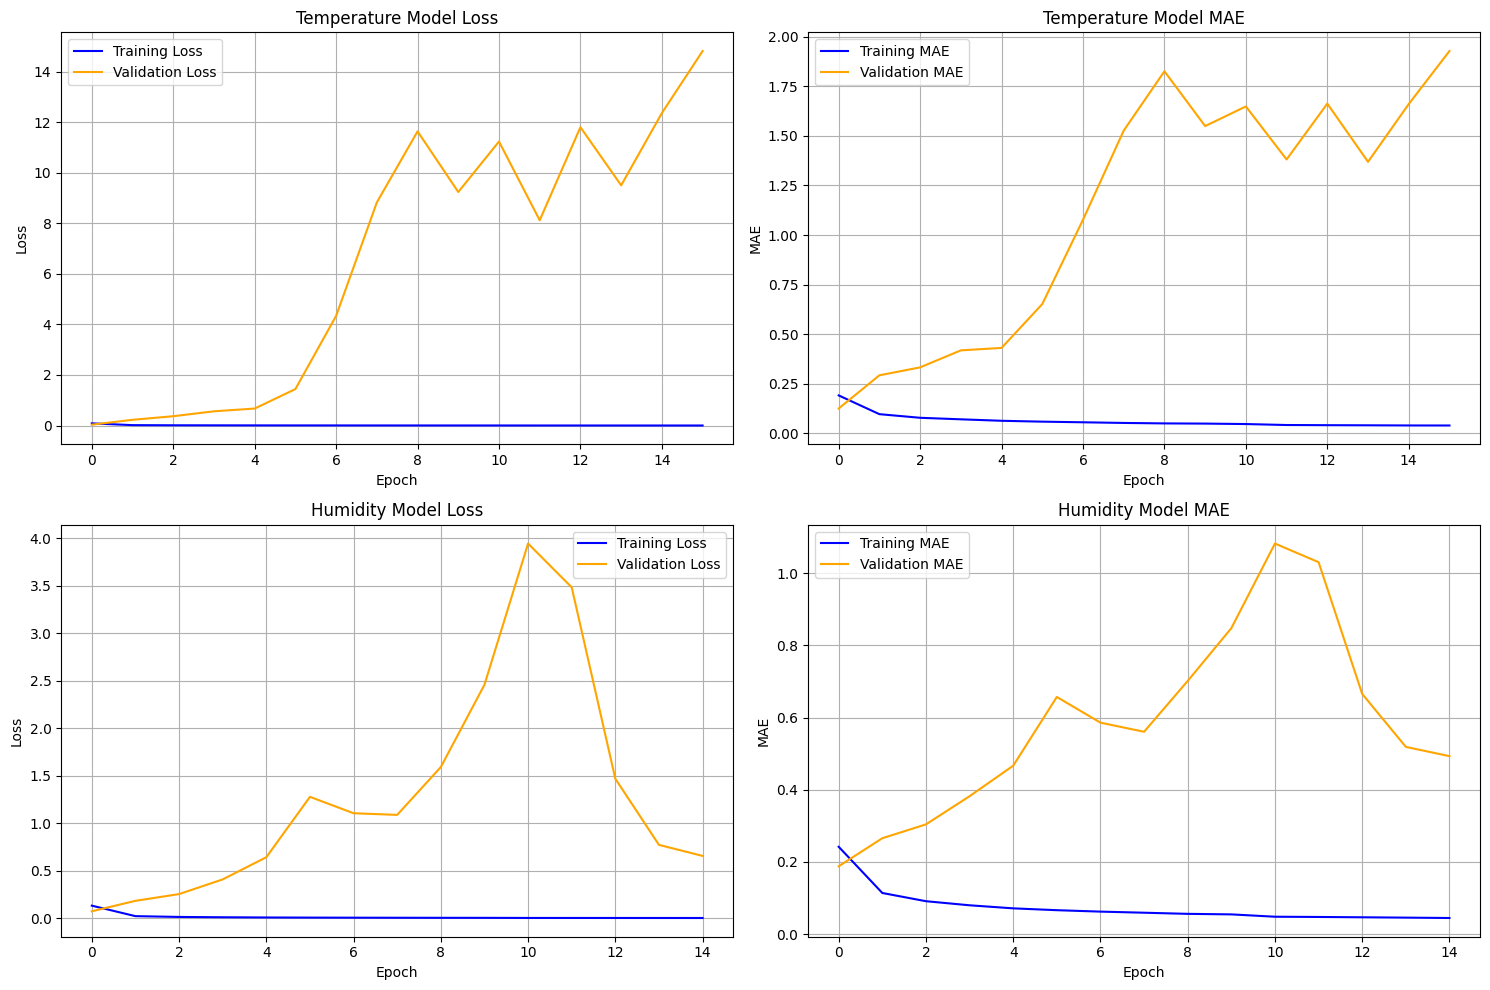


📊 EVALUATING LSTM MODELS

🎯 Indoor_Temp:
   MSE: 3.810
   RMSE: 1.952
   MAE: 1.558
   R2: -1.225

🎯 Indoor_Humidity:
   MSE: 63.625
   RMSE: 7.977
   MAE: 6.774
   R2: -2.088


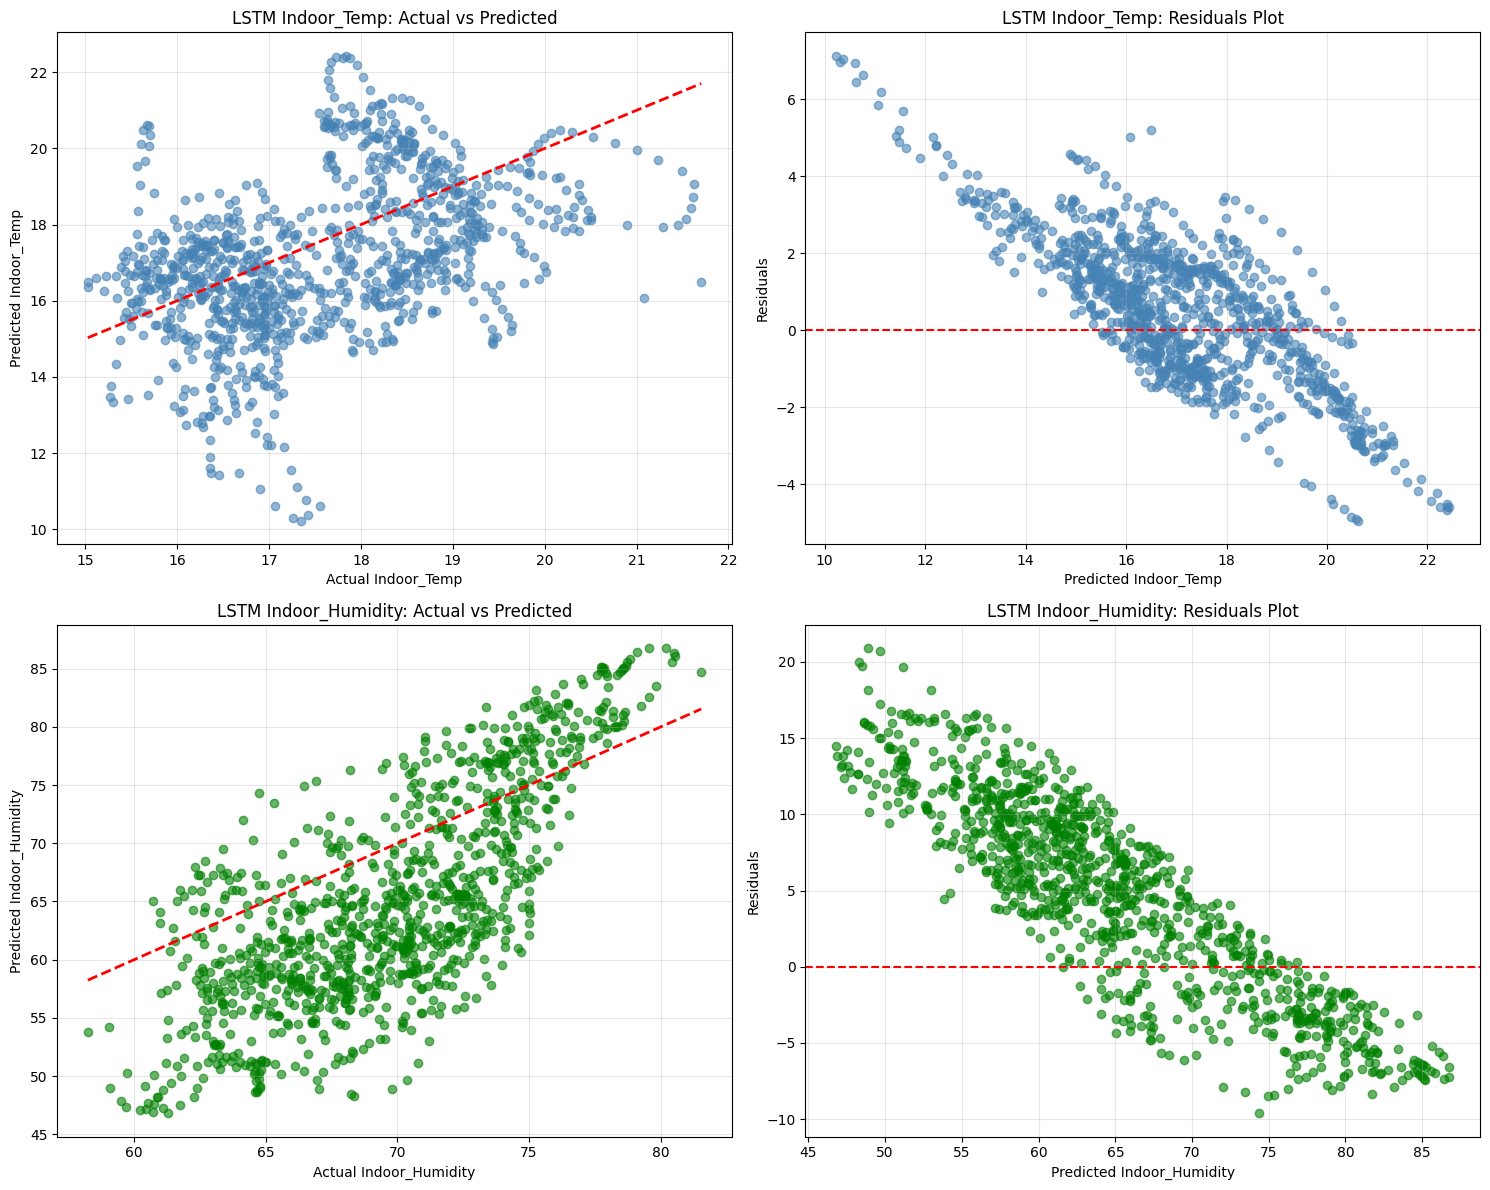

✅ LSTM models saved with prefix: heritage_lstm_predictor


In [13]:
# CELL 3: Main Training Function
def main():
    # Initialize predictor
    predictor = HeritageLSTMPredictor()
    
    # Load and preprocess data
    print("🔄 Loading and preprocessing data...")
    data_dir = r"C:\Users\Riya\Documents\heritage-predictor\env\Data"  # UPDATE THIS PATH
    all_data = predictor.load_and_preprocess_all_data(data_dir)
    
    print(f"📊 Total data points: {len(all_data)}")
    print(f"🏛️ Real data points: {len(all_data[all_data['is_real_data'] == 1])}")
    print(f"🧪 Synthetic data points: {len(all_data[all_data['is_real_data'] == 0])}")
    
    # Prepare features and targets
    X, y_temp, y_humidity, feature_cols = predictor.prepare_features_and_targets(all_data)
    predictor.feature_cols = feature_cols
    print(f"🎯 Number of features: {len(feature_cols)}")
    
    # Strategic data split
    train_data, test_data = predictor.split_data_strategically(all_data)
    
    X_train_df, y_temp_train, y_humidity_train, _ = predictor.prepare_features_and_targets(train_data)
    X_test_df, y_temp_test, y_humidity_test, _ = predictor.prepare_features_and_targets(test_data)
    
    print(f"🏋️ Training set size: {len(X_train_df)}")
    print(f"🧪 Test set size: {len(X_test_df)}")
    
    # Scale features and targets
    print("📏 Scaling features and targets...")
    X_train_scaled = predictor.scaler_X.fit_transform(X_train_df)
    X_test_scaled = predictor.scaler_X.transform(X_test_df)
    
    y_temp_train_scaled = predictor.scaler_temp.fit_transform(y_temp_train.values.reshape(-1, 1)).flatten()
    y_humidity_train_scaled = predictor.scaler_humidity.fit_transform(y_humidity_train.values.reshape(-1, 1)).flatten()
    
    y_temp_test_scaled = predictor.scaler_temp.transform(y_temp_test.values.reshape(-1, 1)).flatten()
    y_humidity_test_scaled = predictor.scaler_humidity.transform(y_humidity_test.values.reshape(-1, 1)).flatten()
    
    # Create sequences for LSTM
    sequence_length = 24  # 24 hours of history
    print(f"🔄 Creating sequences with length {sequence_length}...")
    
    X_train_seq, y_temp_train_seq = predictor.create_sequences(X_train_scaled, y_temp_train_scaled, sequence_length)
    X_train_seq_hum, y_humidity_train_seq = predictor.create_sequences(X_train_scaled, y_humidity_train_scaled, sequence_length)
    
    X_test_seq, y_temp_test_seq = predictor.create_sequences(X_test_scaled, y_temp_test_scaled, sequence_length)
    X_test_seq_hum, y_humidity_test_seq = predictor.create_sequences(X_test_scaled, y_humidity_test_scaled, sequence_length)
    
    # Split training sequences for validation
    val_split_idx = int(0.8 * len(X_train_seq))
    
    X_val_seq = X_train_seq[val_split_idx:]
    X_train_seq = X_train_seq[:val_split_idx]
    y_temp_val_seq = y_temp_train_seq[val_split_idx:]
    y_temp_train_seq = y_temp_train_seq[:val_split_idx]
    
    y_humidity_val_seq = y_humidity_train_seq[val_split_idx:]
    y_humidity_train_seq = y_humidity_train_seq[:val_split_idx]
    
    print(f"📊 Final sequence shapes:")
    print(f"   Training sequences: {X_train_seq.shape[0]}")
    print(f"   Validation sequences: {X_val_seq.shape[0]}")
    print(f"   Test sequences: {X_test_seq.shape[0]}")
    
    # Train LSTM models
    temp_history, humidity_history = predictor.train_lstm_models(
        X_train_seq, y_temp_train_seq, y_humidity_train_seq,
        X_val_seq, y_temp_val_seq, y_humidity_val_seq,
        epochs=100
    )
    
    # Plot training history
    predictor.plot_training_history(temp_history, humidity_history)
    
    # Evaluate models
    metrics = predictor.evaluate_models(X_test_seq, y_temp_test_seq, y_humidity_test_seq)
    
    # Save models
    predictor.save_models("heritage_lstm_predictor")
    
    return predictor, metrics

# Run the main function
if __name__ == "__main__":
    predictor, metrics = main()


🔬 DETAILED REAL DATA ANALYSIS - LSTM
📊 PURE REAL DATA SPLIT:
   Training: 2764 samples
   Testing: 692 samples

🎯 LSTM PERFORMANCE ON PURE REAL DATA:
----------------------------------------
Indoor_Temp:
   MSE: 23.792
   RMSE: 4.878
   MAE: 4.198
   R²: -0.235
Indoor_Humidity:
   MSE: 104.054
   RMSE: 10.201
   MAE: 8.598
   R²: 0.244

📅 MONTHLY LSTM PERFORMANCE (Mean Absolute Error):
       temp_error  humidity_error
month                            
10          4.759           6.209
11          4.541           9.282
12          3.675           8.685


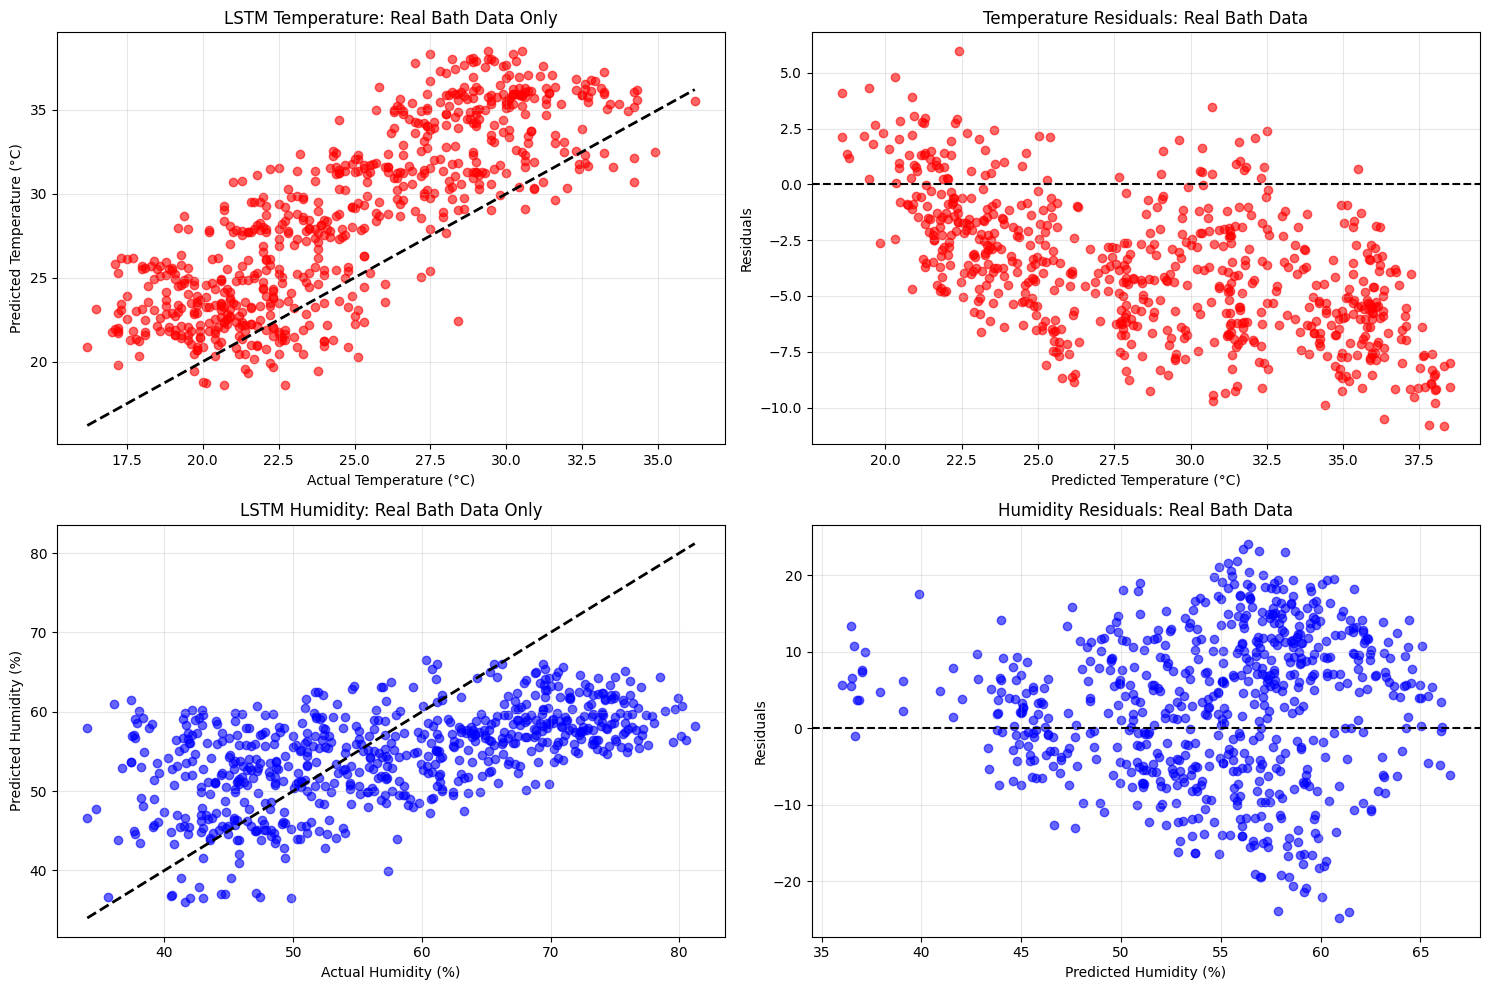

In [14]:
# CELL 5: Detailed Real Data Analysis
def detailed_real_data_analysis_lstm(predictor, all_data):
    """
    Perform detailed analysis of LSTM model performance on real data
    """
    print("🔬 DETAILED REAL DATA ANALYSIS - LSTM")
    print("=" * 50)
    
    # Get only real Bath data
    real_data = all_data[all_data['is_real_data'] == 1].copy()
    real_data = real_data.sort_values('Datetime')
    
    # Prepare features for real data only
    X_real, y_temp_real, y_humidity_real, _ = predictor.prepare_features_and_targets(real_data)
    
    # Split real data chronologically (80/20)
    split_idx = int(len(real_data) * 0.8)
    
    X_real_train = X_real.iloc[:split_idx]
    X_real_test = X_real.iloc[split_idx:]
    y_temp_real_train = y_temp_real.iloc[:split_idx]
    y_temp_real_test = y_temp_real.iloc[split_idx:]
    y_humidity_real_train = y_humidity_real.iloc[:split_idx]
    y_humidity_real_test = y_humidity_real.iloc[split_idx:]
    
    print(f"📊 PURE REAL DATA SPLIT:")
    print(f"   Training: {len(X_real_train)} samples")
    print(f"   Testing: {len(X_real_test)} samples")
    
    # Scale the real data using existing scalers
    X_real_test_scaled = predictor.scaler_X.transform(X_real_test)
    y_temp_real_test_scaled = predictor.scaler_temp.transform(y_temp_real_test.values.reshape(-1, 1)).flatten()
    y_humidity_real_test_scaled = predictor.scaler_humidity.transform(y_humidity_real_test.values.reshape(-1, 1)).flatten()
    
    # Create sequences for LSTM prediction
    sequence_length = 24
    if len(X_real_test_scaled) >= sequence_length:
        X_real_test_seq, y_temp_real_test_seq = predictor.create_sequences(
            X_real_test_scaled, y_temp_real_test_scaled, sequence_length
        )
        X_real_test_seq_hum, y_humidity_real_test_seq = predictor.create_sequences(
            X_real_test_scaled, y_humidity_real_test_scaled, sequence_length
        )
        
        # Make predictions with LSTM models
        temp_predictions = predictor.temp_model.predict(X_real_test_seq, verbose=0).flatten()
        humidity_predictions = predictor.humidity_model.predict(X_real_test_seq_hum, verbose=0).flatten()
        
        # Inverse transform predictions and targets
        y_temp_orig = predictor.scaler_temp.inverse_transform(y_temp_real_test_seq.reshape(-1, 1)).flatten()
        y_humidity_orig = predictor.scaler_humidity.inverse_transform(y_humidity_real_test_seq.reshape(-1, 1)).flatten()
        temp_pred_orig = predictor.scaler_temp.inverse_transform(temp_predictions.reshape(-1, 1)).flatten()
        humidity_pred_orig = predictor.scaler_humidity.inverse_transform(humidity_predictions.reshape(-1, 1)).flatten()
        
        # Calculate metrics
        print(f"\n🎯 LSTM PERFORMANCE ON PURE REAL DATA:")
        print("-" * 40)
        
        # Temperature metrics
        temp_mse = mean_squared_error(y_temp_orig, temp_pred_orig)
        temp_rmse = np.sqrt(temp_mse)
        temp_mae = mean_absolute_error(y_temp_orig, temp_pred_orig)
        temp_r2 = r2_score(y_temp_orig, temp_pred_orig)
        
        print(f"Indoor_Temp:")
        print(f"   MSE: {temp_mse:.3f}")
        print(f"   RMSE: {temp_rmse:.3f}")
        print(f"   MAE: {temp_mae:.3f}")
        print(f"   R²: {temp_r2:.3f}")
        
        # Humidity metrics
        humidity_mse = mean_squared_error(y_humidity_orig, humidity_pred_orig)
        humidity_rmse = np.sqrt(humidity_mse)
        humidity_mae = mean_absolute_error(y_humidity_orig, humidity_pred_orig)
        humidity_r2 = r2_score(y_humidity_orig, humidity_pred_orig)
        
        print(f"Indoor_Humidity:")
        print(f"   MSE: {humidity_mse:.3f}")
        print(f"   RMSE: {humidity_rmse:.3f}")
        print(f"   MAE: {humidity_mae:.3f}")
        print(f"   R²: {humidity_r2:.3f}")
        
        # Seasonal analysis (if enough data)
        if len(y_temp_orig) > 30:  # Need reasonable amount of data
            real_test_with_datetime = real_data.iloc[split_idx + sequence_length - 1:].copy()
            if len(real_test_with_datetime) == len(y_temp_orig):
                real_test_with_datetime['temp_error'] = abs(y_temp_orig - temp_pred_orig)
                real_test_with_datetime['humidity_error'] = abs(y_humidity_orig - humidity_pred_orig)
                
                monthly_performance = real_test_with_datetime.groupby('month').agg({
                    'temp_error': 'mean',
                    'humidity_error': 'mean'
                }).round(3)
                
                print(f"\n📅 MONTHLY LSTM PERFORMANCE (Mean Absolute Error):")
                print(monthly_performance)
        
        # Plot real data predictions
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        
        # Temperature actual vs predicted
        axes[0, 0].scatter(y_temp_orig, temp_pred_orig, alpha=0.6, color='red')
        axes[0, 0].plot([y_temp_orig.min(), y_temp_orig.max()], 
                       [y_temp_orig.min(), y_temp_orig.max()], 'k--', lw=2)
        axes[0, 0].set_xlabel('Actual Temperature (°C)')
        axes[0, 0].set_ylabel('Predicted Temperature (°C)')
        axes[0, 0].set_title('LSTM Temperature: Real Bath Data Only')
        axes[0, 0].grid(True, alpha=0.3)
        
        # Temperature residuals
        temp_residuals = y_temp_orig - temp_pred_orig
        axes[0, 1].scatter(temp_pred_orig, temp_residuals, alpha=0.6, color='red')
        axes[0, 1].axhline(y=0, color='black', linestyle='--')
        axes[0, 1].set_xlabel('Predicted Temperature (°C)')
        axes[0, 1].set_ylabel('Residuals')
        axes[0, 1].set_title('Temperature Residuals: Real Bath Data')
        axes[0, 1].grid(True, alpha=0.3)
        
        # Humidity actual vs predicted
        axes[1, 0].scatter(y_humidity_orig, humidity_pred_orig, alpha=0.6, color='blue')
        axes[1, 0].plot([y_humidity_orig.min(), y_humidity_orig.max()], 
                       [y_humidity_orig.min(), y_humidity_orig.max()], 'k--', lw=2)
        axes[1, 0].set_xlabel('Actual Humidity (%)')
        axes[1, 0].set_ylabel('Predicted Humidity (%)')
        axes[1, 0].set_title('LSTM Humidity: Real Bath Data Only')
        axes[1, 0].grid(True, alpha=0.3)
        
        # Humidity residuals
        humidity_residuals = y_humidity_orig - humidity_pred_orig
        axes[1, 1].scatter(humidity_pred_orig, humidity_residuals, alpha=0.6, color='blue')
        axes[1, 1].axhline(y=0, color='black', linestyle='--')
        axes[1, 1].set_xlabel('Predicted Humidity (%)')
        axes[1, 1].set_ylabel('Residuals')
        axes[1, 1].set_title('Humidity Residuals: Real Bath Data')
        axes[1, 1].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
        
        return y_temp_orig, temp_pred_orig, y_humidity_orig, humidity_pred_orig
        
    else:
        print(f"❌ Not enough real data for sequence analysis (need at least {sequence_length} points)")
        return None, None, None, None

# Run the detailed analysis
y_temp_real, temp_pred_real, y_humidity_real, humidity_pred_real = detailed_real_data_analysis_lstm(predictor, all_data)

In [15]:
# CELL 6: Model Comparison and Summary
def lstm_model_summary(predictor):
    """
    Provide a comprehensive summary of the LSTM models
    """
    print("📋 LSTM MODEL SUMMARY")
    print("=" * 50)
    
    # Model architecture summary
    print("🏗️ MODEL ARCHITECTURE:")
    print("-" * 30)
    print("Temperature Model:")
    predictor.temp_model.summary()
    
    print("\nHumidity Model:")
    predictor.humidity_model.summary()
    
    # Feature information
    if predictor.feature_cols:
        print(f"\n🎯 FEATURE INFORMATION:")
        print(f"   Total features: {len(predictor.feature_cols)}")
        print(f"   Sequence length: 24 hours")
        print(f"   Input shape: (24, {len(predictor.feature_cols)})")
    
    # Material properties summary
    print(f"\n🧱 MATERIAL PROPERTIES:")
    for material, props in predictor.material_properties.items():
        print(f"   {material}: {props['thermal_mass_factor']} thermal mass")
        print(f"      Conductivity: {props['avg_conductivity']:.3f}")
    
    print(f"\n💾 SAVED FILES:")
    print(f"   - heritage_lstm_predictor_temperature_lstm.h5")
    print(f"   - heritage_lstm_predictor_humidity_lstm.h5") 
    print(f"   - heritage_lstm_predictor_lstm_objects.pkl")
    
    print(f"\n✅ LSTM Heritage Building Predictor Complete!")

# Run the model summary
lstm_model_summary(predictor)

📋 LSTM MODEL SUMMARY
🏗️ MODEL ARCHITECTURE:
------------------------------
Temperature Model:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 24, 64)         │        33,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 139,493 (544.90 KB)

 Trainable params: 46,497 (181.63 KB)

 Non-trainable params: 0 (0.00 B)

... (5 outputs left out)

 Trainable params: 46,497 (181.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 92,996 (363.27 KB)


🎯 FEATURE INFORMATION:
   Total features: 66
   Sequence length: 24 hours
   Input shape: (24, 66)

🧱 MATERIAL PROPERTIES:
   Material1: high thermal mass
      Conductivity: 1.667
   Material2: medium thermal mass
      Conductivity: 1.467
   Material3: low thermal mass
      Conductivity: 0.058

💾 SAVED FILES:
   - heritage_lstm_predictor_temperature_lstm.h5
   - heritage_lstm_predictor_humidity_lstm.h5
   - heritage_lstm_predictor_lstm_objects.pkl

✅ LSTM Heritage Building Predictor Complete!


In [16]:
# CELL 7: Future Prediction Function (Optional)
def make_future_predictions(predictor, recent_data, hours_ahead=24):
    """
    Make future predictions using the trained LSTM models
    """
    print(f"🔮 MAKING {hours_ahead} HOUR PREDICTIONS")
    print("=" * 50)
    
    # Prepare the most recent data for prediction
    X_recent, _, _, _ = predictor.prepare_features_and_targets(recent_data.tail(24))
    X_recent_scaled = predictor.scaler_X.transform(X_recent)
    
    # Reshape for LSTM (1 sample, 24 timesteps, n_features)
    X_recent_seq = X_recent_scaled.reshape(1, 24, X_recent_scaled.shape[1])
    
    # Make predictions
    temp_pred_scaled = predictor.temp_model.predict(X_recent_seq, verbose=0)
    humidity_pred_scaled = predictor.humidity_model.predict(X_recent_seq, verbose=0)
    
    # Inverse transform
    temp_pred = predictor.scaler_temp.inverse_transform(temp_pred_scaled)[0, 0]
    humidity_pred = predictor.scaler_humidity.inverse_transform(humidity_pred_scaled)[0, 0]
    
    print(f"🌡️ Predicted Indoor Temperature: {temp_pred:.2f}°C")
    print(f"💧 Predicted Indoor Humidity: {humidity_pred:.2f}%")
    
    return temp_pred, humidity_pred

# Example usage (uncomment to use):
# temp_pred, humidity_pred = make_future_predictions(predictor, all_data)

print("🎉 ALL LSTM CELLS COMPLETED SUCCESSFULLY!")
print("=" * 50)
print("You now have a complete LSTM heritage building predictor!")
print("Key differences from Random Forest:")
print("- Uses temporal sequences (24 hours of history)")
print("- Separate models for temperature and humidity")  
print("- Deep learning approach vs tree-based")
print("- Better for capturing temporal patterns")

🎉 ALL LSTM CELLS COMPLETED SUCCESSFULLY!
You now have a complete LSTM heritage building predictor!
Key differences from Random Forest:
- Uses temporal sequences (24 hours of history)
- Separate models for temperature and humidity
- Deep learning approach vs tree-based
- Better for capturing temporal patterns
